# Explore here

In [1]:
# Cargamos los datos de ventas que nos facilita la academia
import pandas as pd

url = "https://breathecode.herokuapp.com/asset/internal-link?id=2546&path=sales.csv"
total_data = pd.read_csv(url)




In [2]:
total_data.head()

,date,sales
0,2022-09-03 17:10:08.079328,55.292157
1,2022-09-04 17:10:08.079328,53.803211
2,2022-09-05 17:10:08.079328,58.141693
3,2022-09-06 17:10:08.079328,64.530899
4,2022-09-07 17:10:08.079328,66.013633


In [3]:
# Convertimos las fechas para poder trabajar con ellas
total_data["date"] = pd.to_datetime(total_data["date"])

# Ponemos las fechas como índice de nuestros datos
total_data = total_data.set_index("date")

# Nos quedamos con las ventas para crear la serie temporal
ts = total_data["sales"]

# Vemos cómo ha quedado
ts.head(60)

date
2022-09-03 17:10:08.079328     55.292157
2022-09-04 17:10:08.079328     53.803211
2022-09-05 17:10:08.079328     58.141693
2022-09-06 17:10:08.079328     64.530899
2022-09-07 17:10:08.079328     66.013633
2022-09-08 17:10:08.079328     60.081865
2022-09-09 17:10:08.079328     68.466704
2022-09-10 17:10:08.079328     67.765106
2022-09-11 17:10:08.079328     70.512261
2022-09-12 17:10:08.079328     74.656453
2022-09-13 17:10:08.079328     76.459528
2022-09-14 17:10:08.079328     82.992958
2022-09-15 17:10:08.079328     83.515990
2022-09-16 17:10:08.079328     84.200641
2022-09-17 17:10:08.079328     87.769946
2022-09-18 17:10:08.079328     90.042119
2022-09-19 17:10:08.079328     96.126073
2022-09-20 17:10:08.079328     93.631101
2022-09-21 17:10:08.079328     97.788518
2022-09-22 17:10:08.079328     96.889768
2022-09-23 17:10:08.079328     94.395825
2022-09-24 17:10:08.079328    106.618390
2022-09-25 17:10:08.079328    109.853583
2022-09-26 17:10:08.079328    107.636519
2022-09-27 

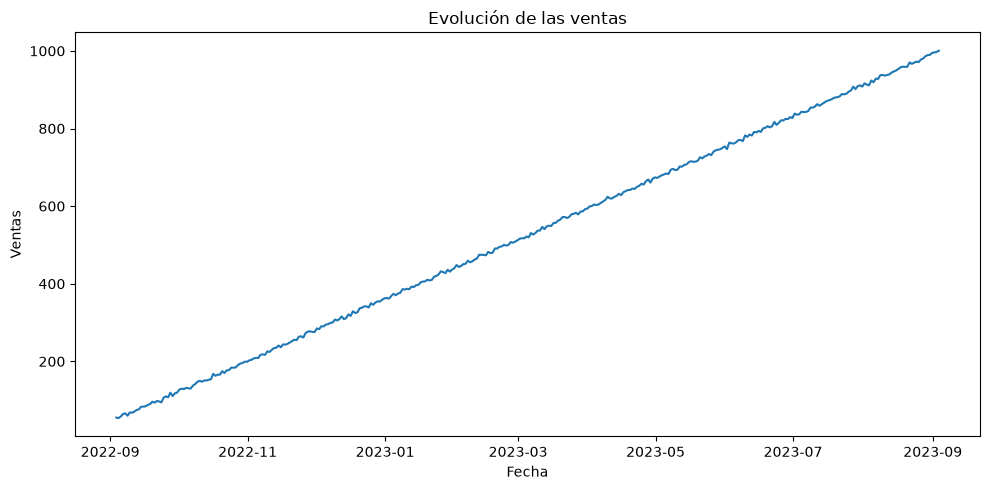

In [4]:
# Representamos las ventas a lo largo del tiempo
import matplotlib.pyplot as plt
import seaborn as sns

fig, axis = plt.subplots(figsize = (10, 5))

sns.lineplot(data = ts)

plt.title("Evolución de las ventas")
plt.xlabel("Fecha")
plt.ylabel("Ventas")

plt.tight_layout()
plt.show()

Las ventas muestran una tendencia claramente ascendente durante todo el periodo. El crecimiento es bastante constante, con pequeñas variaciones y sin caídas importantes. Esto indica que la empresa está aumentando sus ventas de forma sostenida.


In [5]:
# Comprobamos si nuestra serie de ventas es estacionaria
from statsmodels.tsa.stattools import adfuller

def test_stationarity(timeseries):
    print("Resultados de la prueba de Dickey-Fuller:")

    dftest = adfuller(timeseries, autolag="AIC")

    dfoutput = pd.Series(
        dftest[0:4],
        index=["Test Statistic", "p-value", "#Lags Used", "Number of Observations Used"]
    )

    for key, value in dftest[4].items():
        dfoutput["Critical Value (%s)" % key] = value

    return dfoutput

# Aplicamos la prueba a nuestras ventas
test_stationarity(ts)

Resultados de la prueba de Dickey-Fuller:


/tmp/ipykernel_9866/3232311834.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag="AIC")


Test Statistic                   0.545414
p-value                          0.986190
#Lags Used                      13.000000
Number of Observations Used    352.000000
Critical Value (1%)             -3.449065
Critical Value (5%)             -2.869786
Critical Value (10%)            -2.571163
dtype: float64

La prueba de Dickey-Fuller devuelve un p-value de 0,986, superior a 0,05. Por tanto, no podemos considerar estacionaria nuestra serie. Esto coincide con el gráfico anterior, donde observamos un crecimiento continuo de las ventas.

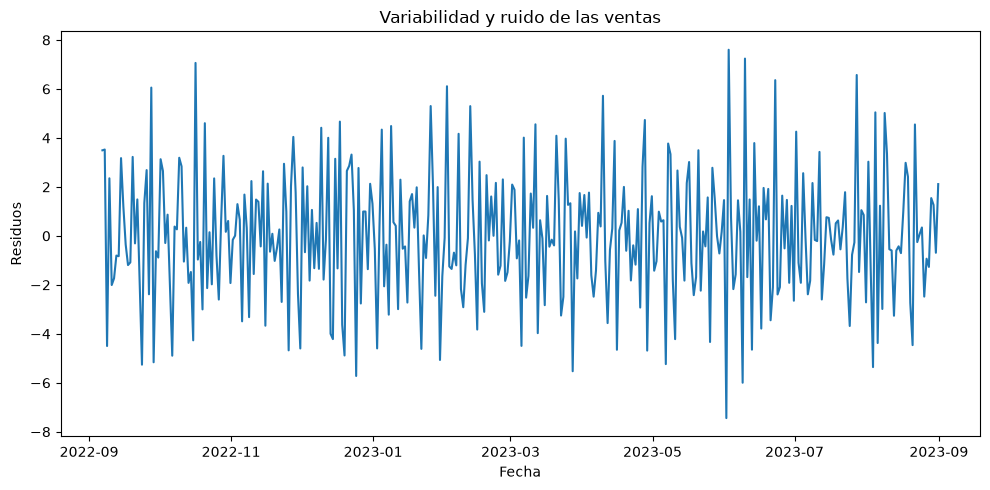

In [6]:
# Separamos la serie para estudiar las variaciones de las ventas
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(ts, period=7)

# Nos quedamos con las variaciones que no explica la tendencia ni el patrón semanal
residual = decomposition.resid

# Representamos estas variaciones en un gráfico
fig, axis = plt.subplots(figsize=(10, 5))

sns.lineplot(data=residual)

plt.title("Variabilidad y ruido de las ventas")
plt.xlabel("Fecha")
plt.ylabel("Residuos")

plt.tight_layout()
plt.show()

Observamos que los residuos oscilan alrededor de cero, con pequeñas variaciones positivas y negativas. Aparecen algunos picos, pero no se aprecia una tendencia clara en ellos. Las fluctuaciones son relativamente pequeñas comparadas con el crecimiento general de las ventas.

In [7]:
# Separamos las ventas para entrenar y comprobar el modelo
train_size = int(len(ts) * 0.8)

train = ts.iloc[:train_size]
test = ts.iloc[train_size:]

# Vemos cuántos datos tenemos en cada grupo
print("Datos de entrenamiento:", len(train))
print("Datos de prueba:", len(test))

Datos de entrenamiento: 292
Datos de prueba: 74


In [8]:
# Calculamos los cambios diarios de las ventas de entrenamiento
train_stationary = train.diff().dropna()

# Comprobamos si estos cambios son estacionarios
test_stationarity(train_stationary)

Resultados de la prueba de Dickey-Fuller:


/tmp/ipykernel_9866/3232311834.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag="AIC")


Test Statistic                -1.268120e+01
p-value                        1.185940e-23
#Lags Used                     6.000000e+00
Number of Observations Used    2.840000e+02
Critical Value (1%)           -3.453587e+00
Critical Value (5%)           -2.871771e+00
Critical Value (10%)          -2.572222e+00
dtype: float64

In [11]:
# Buscamos un modelo ARIMA adecuado para nuestras ventas
from pmdarima import auto_arima

model = auto_arima(
    train,
    seasonal=False,
    trace=True
)

# Vemos el resumen del modelo elegido
model.summary()

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.93 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1675.428, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1578.564, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1475.165, Time=0.21 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1763.761, Time=0.01 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=1475.512, Time=0.19 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=1475.495, Time=0.19 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=1479.028, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=1762.924, Time=0.05 sec

Best model:  ARIMA(0,1,1)(0,0,0)[0] intercept
Total fit time: 2.192 seconds


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  292
Model:               SARIMAX(0, 1, 1)   Log Likelihood                -734.582
Date:                Thu, 29 Oct 2026   AIC                           1475.165
Time:                        06:52:45   BIC                           1486.185
Sample:                    09-03-2022   HQIC                          1479.579
                         - 06-21-2023                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      2.5984      0.011    243.641      0.000       2.577       2.619
ma.L1         -0.9439      0.021    -44.117      0.000      -0.986      -0.902
sigma2         9.0537      0.817     11.084      0.000       7.453      10.655
===================================================================================
Ljung-Box (L1) (Q):                   1.34   Jarque-Bera (JB):                 1.24
Prob(Q):                              0.25   Prob(JB):                         0.54
Heteroskedasticity (H):               0.95   Skew:                             0.06
Prob(H) (two-sided):                  0.81   Kurtosis:                         2.70
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [12]:
# Predecimos las ventas de los 74 días que reservamos
forecast = model.predict(n_periods=len(test))

# Organizamos las predicciones con sus fechas
forecast = pd.Series(list(forecast), index=test.index)

# Comparamos las primeras ventas reales con las previstas
comparacion = pd.DataFrame({
    "Ventas reales": test,
    "Predicción": forecast
})

comparacion.head()

,Ventas reales,Predicción
date,,
2023-06-22 17:10:08.079328,816.911750,810.107776
2023-06-23 17:10:08.079328,809.422692,812.706154
2023-06-24 17:10:08.079328,814.797630,815.304531
2023-06-25 17:10:08.079328,821.218893,817.902909
2023-06-26 17:10:08.079328,820.704134,820.501287


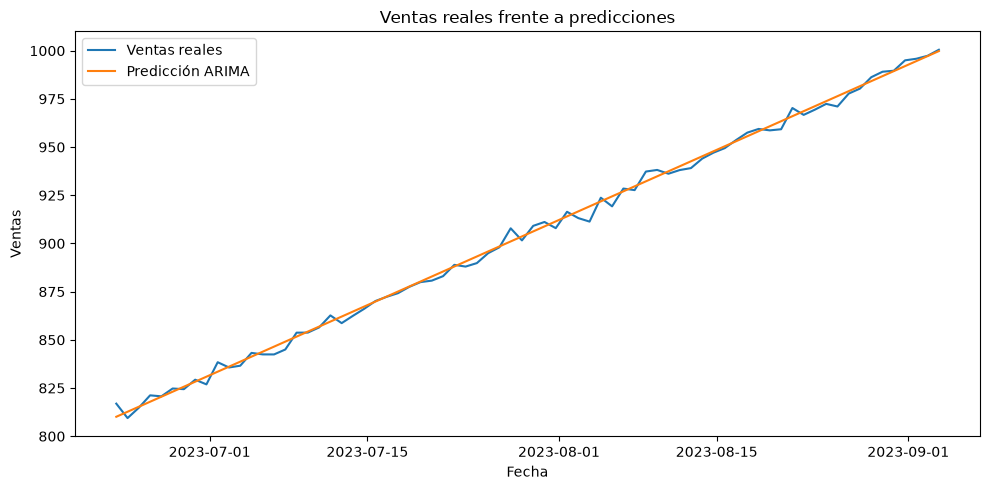

In [13]:
# Comparamos las ventas reales con las predicciones de ARIMA
fig, axis = plt.subplots(figsize=(10, 5))

sns.lineplot(data=test, label="Ventas reales")
sns.lineplot(data=forecast, label="Predicción ARIMA")

plt.title("Ventas reales frente a predicciones")
plt.xlabel("Fecha")
plt.ylabel("Ventas")

plt.tight_layout()
plt.show()

In [14]:
# Calculamos cuánto se equivoca nuestro modelo al predecir las ventas
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(test, forecast)

# Mostramos el error medio de las predicciones
print("Error medio de ARIMA:", round(mae, 2))

Error medio de ARIMA: 2.23


Resultados del modelo ARIMA

Hemos entrenado un modelo ARIMA (0,1,1) para predecir las ventas de la empresa.

Al comparar las predicciones con los 74 días de prueba, hemos obtenido un error medio absoluto (MAE) de 2,23.

El modelo sigue bastante bien la tendencia creciente de las ventas, con diferencias pequeñas respecto a los valores reales.

In [15]:
# Guardamos nuestro modelo ARIMA para poder utilizarlo más adelante
import joblib
from pathlib import Path

# Localizamos la carpeta models del proyecto
carpeta = Path("models") if Path("models").exists() else Path("../models")

# Guardamos el modelo entrenado
joblib.dump(model, carpeta / "modelo_arima.pkl")

['../models/modelo_arima.pkl']